# Notebook for initial GRU implementation

In [1]:
import sys
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0,str(ROOT))
OUT = ROOT / "lanes" / "C_memory" / "outputs"
OUT.mkdir(exist_ok=True)

from carfollow import (load_table, split_by_group, iter_pairs, HISTORY_FEATURES, HISTORY_STEPS, history_at, DT, check_model)
from lanes.C_memory.gru import GRUFollower, GRUDriver, save_model, load_model

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

## Read in the data using imported functions

In [2]:
# Define splits
TEST_GROUP = 0
VAL_GROUP = (TEST_GROUP - 1) % 5

# reading data in and creating the trainning and test split by group number using split_by_group
data_df = load_table(ROOT / "data" / "full" / "pairs_full.csv")

train_val , test_df = split_by_group(data_df, test_group=TEST_GROUP)
train_df, val_df = split_by_group(train_val, test_group=VAL_GROUP)

# Making sure the groups split upt correctly
print("Groups", test_df['driver_group'].unique(), "Length: ", len(test_df))
print("Groups", val_df['driver_group'].unique(), "Length: ", len(val_df))
print("Groups", train_df['driver_group'].unique(), "Length: ", len(train_df))

assert len(data_df) == (len(test_df) + len(train_df) + len(val_df))

Groups [0] Length:  735051
Groups [4] Length:  740454
Groups [3 1 2] Length:  2201977


In [3]:
# Creating windows to feed into model --> Looking back 3 seconds
def make_windows(df, lookback_steps=HISTORY_STEPS, feature_cols=HISTORY_FEATURES):
    """
    Slicing every pair into windows of lookback_steps rows

    Returns:
        X: array of n windows, with look_backsteps, 3 (# num features)
        Y: array of target accel_mps2 at each window's last row
    """
    X, y = [], []
    for pair in iter_pairs(df):
        
        # Putting raw values into numpy arrays for efficiency  --> float 32
        features = pair[list(feature_cols)].to_numpy(np.float32) 
        acceleration = pair["accel_mps2"].to_numpy(np.float32)

        # Every row in data represents 0.1s of time passing
        # Starting at 29 --> 30 rows before prediction
        for i in range(lookback_steps - 1, len(pair) - 1):
            # Grab the rows
            window = features[i - lookback_steps + 1: i + 1]
            X.append(window)
            # Target acceleration
            y.append(acceleration[i])
    return np.stack(X), np.array(y)

In [4]:
X_train, y_train = make_windows(train_df)
X_val, y_val = make_windows(val_df)
X_test, y_test = make_windows(test_df)

# Checking shape
print(X_train.shape, X_test.shape, X_val.shape)
print(y_train.shape, y_test.shape, y_val.shape)

(2052577, 30, 3) (685851, 30, 3) (690024, 30, 3)
(2052577,) (685851,) (690024,)


In [5]:
BATCH_SIZE = 256

# Need to normalize values before feeding to the GRU model
# Currently Gap is in meters and has much larger range than both speed and closing speed in m/s
mean = X_train.reshape(-1, 3).mean(0)
std = X_train.reshape(-1,3).std(0)

print(mean.round(3),  std.round(3))


def load_data(X, y, shuffle):
    """
    normalizes and uses dataloader to prepare data for model
    """
    X_normalized = torch.from_numpy(((X - mean) / std).astype(np.float32))
    return DataLoader(TensorDataset(X_normalized, torch.tensor(y)), batch_size=BATCH_SIZE, shuffle=shuffle)

# train_dl = load_data(X_train, y_train, True)
# val_dl = load_data(X_val, y_val, False)
# test_dl = load_data(X_test, y_test, False)
xb, yb = next(iter(load_data(X_train[:BATCH_SIZE], y_train[:BATCH_SIZE], False)))
print(xb.shape, yb.shape)

# Free up memory of dataframes we wont use anymore
del data_df, train_val, train_df, val_df

[10.478  4.952 -0.132] [11.022  5.133  1.192]
torch.Size([256, 30, 3]) torch.Size([256])


### Training the GRU model set up in gru.py

In [6]:
# Testing import
print(GRUFollower()(xb).shape)

torch.Size([256])


In [7]:
loss_func= nn.MSELoss()

def mse(model, dl):
    """Average squared error over every window in dl --> loader"""
    model.eval()
    total_loss, n = 0.0, 0
    with torch.no_grad():
        for x, y in dl:
            total_loss += loss_func(model(x), y).item() * len(y)
            n += len(y)
    return total_loss / n 

In [8]:
LEARNING_RATE = 1e-3
EPOCHS = 100
MAX_WAIT = 5
MIN_IMPROVE = 1e-3

def train_gru(k, max_epochs=EPOCHS, max_wait=MAX_WAIT, min_improvement=MIN_IMPROVE):
    """Train GRU model with k nearest rows of each window --> So we can change how far we are looking back"""
    torch.manual_seed(SEED)    
    model_k = GRUFollower()
    opt = torch.optim.Adam(model_k.parameters(), lr=LEARNING_RATE)
    
    # Adjusting based on window given --> k
    train_dl_k = load_data(X_train[:, -k:], y_train, True)
    val_dl_k = load_data(X_val[:, -k:], y_val, False)

    
    # Building path
    out_path = OUT / f"gru_w{k}_{TEST_GROUP}.pt"
    
    # Keeping track of history and best mse
    best = float("inf")
    bad_streak = 0 # Going to keep track of epochs where loss doesn't improve and cut it off there
    history = [] # going to store here to plot later

    for epoch in range(max_epochs):
        model_k.train()
        running, n = 0.0, 0
        for xb, yb in train_dl_k:
            opt.zero_grad()
            loss = loss_func(model_k(xb), yb)
            loss.backward()
            opt.step()
            # to average batch losses
            running += loss.item() * len(yb)
            n += len(yb)
            if n % (256 * 1000) == 0:
                print(f"  {n:,} windows, running loss {running / n:.4f}")
        
        train_mse = running / n
        val_mse = mse(model_k, val_dl_k)
        history.append((train_mse, val_mse))
        
        print(f"Epoch: {epoch} Training Loss (MSE): {train_mse:.4f} Validation Loss (MSE): {val_mse:.4f}")
        
        if val_mse < best * (1- min_improvement): #improvement
            best = val_mse
            torch.save(model_k.state_dict(), out_path)
            bad_streak = 0 # reset bad streak
        else:
            bad_streak += 1 # no real improvement
            if bad_streak >= max_wait:
                print(f"Training stopped early due to a stagnation in the drop of loss after {max_wait} epochs")
                break

    
    # Save model and history and return
    model_k.load_state_dict(torch.load(out_path))
    # saving related std and mean
    np.save(OUT / f"gru_w{k}_{TEST_GROUP}_history.npy", np.array(history))

    return model_k, history

In [9]:
def load_gru(k):
    """Load a trained model from output folder"""
    path = OUT / f"gru_w{k}_{TEST_GROUP}.pt"
    if path.exists():
        model_k = GRUFollower()
        model_k.load_state_dict(torch.load(path))
        history = np.load(OUT / f'gru_w{k}_{TEST_GROUP}_history.npy').tolist()
        return model_k, history
    # Otherwise train new model
    return train_gru(k)

In [10]:
def plot_curve(lookbacks, histories):
    fig, axes = plt.subplots(1, len(lookbacks), figsize=(12, 3.5), sharey=True)
    for ax, k in zip(axes, lookbacks):
        # PLotting training
        train_curve, val_curve = zip(*histories[k])
        ax.plot(train_curve, label='train')
        ax.plot(val_curve, label='validation')
        ax.set_title(f"{k} rows")
        ax.set_yscale('log')
        ax.set_xlabel('epochs')
    axes[0].set_ylabel('Mean Squared Error (MSE)')
    axes[0].legend()
    plt.tight_layout()
    plt.show()

### Test on new drivers

In [11]:
def predict(model, dl):
    """Get model predictions for every window in order from dataloader"""
    model.eval()
    with torch.no_grad():
        return torch.cat([model(xb) for xb, _ in dl]).numpy()

def score_next_predictions(name, pred):
    """Scoring each prediction and printing out metrics"""
    # Mean absolute error
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    print(f"{name:50s}: MAE: {mae:.4f} RMSE: {rmse:.4f} R2: {r2:.4f}")

### Start Model training

In [12]:
LOOKBACKS = [30, 2, 1]
models , histories = {}, {}
for k in LOOKBACKS:
    models[k], histories[k] = load_gru(k)

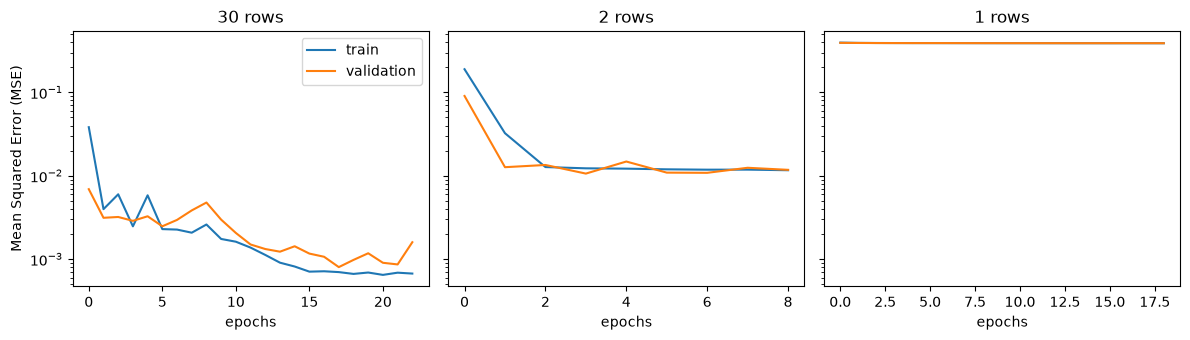

In [13]:
plot_curve(LOOKBACKS, histories)

In [14]:
# Baseline scores
zero_pred = np.zeros_like(y_test)
last_accel = (X_test[:, -1, 1] - X_test[:, -2, 1]) / DT
score_next_predictions("Predict 0 (Keep Speed)", zero_pred)
score_next_predictions("Repeat last accel (Constant Acceleration)", last_accel)

# Score the models
preds = {}
for k in LOOKBACKS:
    preds[k] = predict(models[k], load_data(X_test[:, -k:], y_test, False))
    score_next_predictions(f"GRU with {k} rows: ", preds[k])

Predict 0 (Keep Speed)                            : MAE: 0.5377 RMSE: 0.7420 R2: -0.0055
Repeat last accel (Constant Acceleration)         : MAE: 0.0744 RMSE: 0.1050 R2: 0.9799
GRU with 30 rows:                                 : MAE: 0.0155 RMSE: 0.0288 R2: 0.9985
GRU with 2 rows:                                  : MAE: 0.0745 RMSE: 0.1026 R2: 0.9808
GRU with 1 rows:                                  : MAE: 0.4685 RMSE: 0.6232 R2: 0.2908


In [15]:
print(f"Number of tests: {len(y_test)}")
# Outlier count
print("Outlier Count (Outside 8 m/s^2): ", (np.abs(y_test) > 8).sum())
print("Total percentage of oultiers: ", (((np.abs(y_test) > 8).sum()) / len(y_test)).round(6))

Number of tests: 685851
Outlier Count (Outside 8 m/s^2):  36
Total percentage of oultiers:  5.2e-05


In [16]:
# Last bit here is to save models with everything they need to be loaded into the scorer
# Also loads it back the way the scorer would and makes sure predictions haven't changed

for k in LOOKBACKS:
    driver = GRUDriver(models[k], mean, std, lookback=k)
    path = OUT / f"gru_w{k}_{TEST_GROUP}_handoff.pt"
    save_model(driver, path)

    reloaded = load_model(path)
    check_model(reloaded)
    biggest_diff = np.abs(reloaded.accel_batch(X_test[:1000]) - preds[k][:1000]).max()
    print(f"{reloaded.name}: Saved to path {path.name}, max difference vs notebook = {biggest_diff:.1e}")

gru_w30: Saved to path gru_w30_0_handoff.pt, max difference vs notebook = 0.0e+00
gru_w2: Saved to path gru_w2_0_handoff.pt, max difference vs notebook = 0.0e+00
gru_w1: Saved to path gru_w1_0_handoff.pt, max difference vs notebook = 0.0e+00
